# Horas semanales de los asalariados a tiempo completo

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "horas-semanales-tiempo-completo"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Horas semanales de los asalariados a tiempo completo"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Horas a la semana"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La media de horas que trabajan habitualmente a la semana, en su empleo principal, los asalariados a tiempo completo de 15 a 64 años, según las encuestas de población activa.

**Cómo se lee.** Son horas **habituales** (las de una semana normal, con las horas extraordinarias que se hacen de forma regular), no las efectivas de una semana concreta. Es el dato más cercano a la jornada máxima legal: en España, cuarenta horas semanales de promedio en cómputo anual (Estatuto de los Trabajadores, artículo 34).

**Limitaciones.**
- Solo cuenta a los asalariados a tiempo completo: no recoge el efecto del tiempo parcial ni de los autónomos.
- Lo que cada persona entiende por horas habituales y la frontera entre tiempo completo y parcial (que declara la persona encuestada) varían entre países.

## 2. Descarga

- **España, EE. UU., Canadá y OCDE:** OCDE, horas trabajadas (`OECD.ELS.SAE,DSD_HW@DF_AVG_USL_WK_WKD`, versión 1.0): media de horas habituales (`USUAL`, `MEAN`) a la semana en el empleo principal (`MAIN`) de los asalariados (`ICSE93_1`) a tiempo completo (`FT`), de 15 a 64 años, ambos sexos.
- **UE-27:** Eurostat `lfsa_ewhuis`: media de horas habituales en el empleo principal de los asalariados (`SAL`) a tiempo completo (`FT`), todas las ocupaciones (`isco08=TOTAL`), de 15 a 64 años. El config nombra `lfsa_ewhuna`, que solo llega a 2008 (CNAE-1993); `lfsa_ewhuis` cubre todos los años con el mismo concepto (anotado en `pending.md`).
- **Solo para las notas:** Eurostat `lfsa_ewhuis` para España, para compararlo con la OCDE.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd

AREAS_OCDE = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde"}
DATAFLOW_HW = "OECD.ELS.SAE,DSD_HW@DF_AVG_USL_WK_WKD,1.0"
# Dimensiones: país . medida . unidad . sexo . edad . situación . periodo . tipo de horas . situación profesional
#              . jornada . operación . tramos de horas . empleo (el dataflow no tiene dimensión de frecuencia)
CLAVE_HW = "{AREA}.HW.H_WK_PS._T.Y15T64.EMP.W.USUAL.ICSE93_1.FT.MEAN._Z.MAIN"
FILTROS_EU = {"isco08": "TOTAL", "wstatus": "SAL", "worktime": "FT", "age": "Y15-64", "sex": "T", "unit": "HR"}

oc, fuentes_oc = oecd.get(DATAFLOW_HW, CLAVE_HW, areas=AREAS_OCDE, desde=DESDE)
eu, fuentes_eu = eurostat.get("lfsa_ewhuis", FILTROS_EU, geos={"EU27_2020": "ue27"}, desde=DESDE)
eu_esp, _ = eurostat.get("lfsa_ewhuis", FILTROS_EU, geos={"ES": "espana"}, desde=DESDE)  # solo para las notas
from lib.tipos import FuenteMeta
print(oc.groupby("serie")["periodo"].agg(["min", "max"]))
print(eu.groupby("serie")["periodo"].agg(["min", "max"]))

         min   max
serie             
canada  2009  2025
eeuu    1979  2025
espana  1987  2025
ocde    2009  2025
        min   max
serie            
ue27   2002  2025


## 3. Transformación

1. Las series se usan tal como las publican las fuentes, en horas a la semana. La OCDE no publica la UE-27 en este dataflow y se usa Eurostat.
2. **Comparación de España** en la OCDE y en Eurostat, para las notas.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


# La OCDE publica Canadá con valor 0 en todos los años (no es un dato): se quita y la serie queda sin dato
ceros = sorted(oc.loc[oc["valor"] == 0, "serie"].unique())
oc = oc[oc["valor"] != 0]
fuentes_oc = [f for f in fuentes_oc if f.serie in set(oc["serie"])]
sin_dato = {s: (oecd.ORGANISMO, "DSD_HW@DF_AVG_USL_WK_WKD: publica 0 horas en todos los años (sin dato)", oecd.URL_EXPLORER)
            for s in ceros if s not in set(oc["serie"])}
HOY = fuentes_eu[0].fecha_consulta
df = pd.concat([oc, eu, pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})], ignore_index=True)
fuentes = [*fuentes_oc, *fuentes_eu, *[FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]]
assert df["valor"].dropna().between(20, 70).all(), "horas fuera de rango"
print("Series con valor 0 en la OCDE (sin dato):", ceros)

NOTAS = [
    "España, EE. UU., Canadá y OCDE: OCDE, horas trabajadas (DSD_HW@DF_AVG_USL_WK_WKD): media de horas habituales a la "
    "semana en el empleo principal de los asalariados a tiempo completo de 15 a 64 años.",
    "UE-27: Eurostat (lfsa_ewhuis), media de horas habituales en el empleo principal de los asalariados a tiempo "
    "completo de 15 a 64 años, agregado de composición actual (EU27_2020).",
    nota_comparacion("Comparación de España en la OCDE y en Eurostat", serie(oc, "espana"), serie(eu_esp, "espana"), 1),
    "Son horas habituales, no efectivas: no descuentan vacaciones, festivos ni bajas. La jornada máxima legal en España "
    "es de cuarenta horas semanales de promedio en cómputo anual (Estatuto de los Trabajadores, artículo 34).",
    "La frontera entre tiempo completo y tiempo parcial la declara la persona encuestada y varía entre países.",
]
if "canada" in sin_dato:
    NOTAS.append("Canadá: la OCDE publica este indicador con valor 0 en todos los años, que no es un dato; la serie queda vacía.")
for n in NOTAS:
    print("-", n)

Series con valor 0 en la OCDE (sin dato): ['canada']
- España, EE. UU., Canadá y OCDE: OCDE, horas trabajadas (DSD_HW@DF_AVG_USL_WK_WKD): media de horas habituales a la semana en el empleo principal de los asalariados a tiempo completo de 15 a 64 años.
- UE-27: Eurostat (lfsa_ewhuis), media de horas habituales en el empleo principal de los asalariados a tiempo completo de 15 a 64 años, agregado de composición actual (EU27_2020).
- Comparación de España en la OCDE y en Eurostat: en los 39 años comunes (1987-2025), la diferencia máxima es de 0,2 puntos, en 2019.
- Son horas habituales, no efectivas: no descuentan vacaciones, festivos ni bajas. La jornada máxima legal en España es de cuarenta horas semanales de promedio en cómputo anual (Estatuto de los Trabajadores, artículo 34).
- La frontera entre tiempo completo y tiempo parcial la declara la persona encuestada y varía entre países.
- Canadá: la OCDE publica este indicador con valor 0 en todos los años, que no es un dato; la serie que

## 4. Visualización

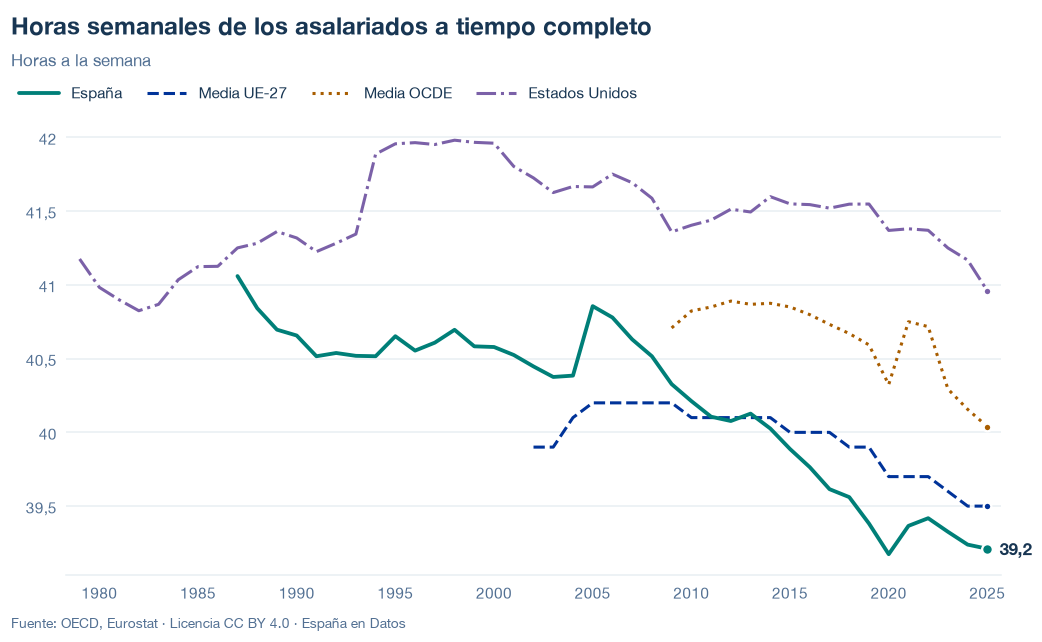

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/horas-semanales-tiempo-completo.json y data/horas-semanales-tiempo-completo.csv


## 6. Fuentes, notas y licencia

- OCDE, horas trabajadas: `OECD.ELS.SAE,DSD_HW@DF_AVG_USL_WK_WKD,1.0` (`HW`, `H_WK_PS`, `_T`, `Y15T64`, `EMP`, `W`, `USUAL`, `ICSE93_1`, `FT`, `MEAN`, `_Z`, `MAIN`).
- Eurostat, `lfsa_ewhuis` (`isco08=TOTAL`, `SAL`, `FT`, `Y15-64`, `T`, `HR`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.